# Assignment 1: Data Profiling and Quality Remediation

## UCI Adult Census Income Dataset

**Course:** TTTC3213 Python for Data Engineering

### Team Members

| Name | Matric Number |
|---|---|
| Wei Zhihang | A206275 |

In [1]:
import sys
from pathlib import Path

print("Python version:", sys.version.split()[0])
print("Python executable:", sys.executable)
print("Working directory:", Path.cwd())

Python version: 3.12.8
Python executable: /Users/zhihangwei/Desktop/assignment1-data-profiling/.venv/bin/python
Working directory: /Users/zhihangwei/Desktop/assignment1-data-profiling


## 1. Scenario

A research team wants to check whether historical census-income data is suitable for an educational income-classification study. The dataset contains missing information and sensitive demographic fields, and requires checks for outliers, duplicates and inconsistent formats. We will identify these problems, justify our handling decisions and assess the remaining privacy and bias risks.

## 2. Data Source

**Dataset:** Adult, UCI Machine Learning Repository.

**Source:** https://archive.ics.uci.edu/dataset/2/adult

**Download:** https://archive.ics.uci.edu/static/public/2/adult.zip

**Method:** Download the official ZIP using Python and keep the original files unchanged.

**Why selected:** This public dataset provides real missing values, numerical fields for outlier checks and demographic fields for privacy and bias assessment. It is not our capstone dataset.

**Limitation:** The data comes from the 1994 US Census database and does not represent current Malaysian residents.

**License:** CC BY 4.0.

**Reference:** Becker, B., & Kohavi, R. (1996). *Adult* [Data set]. UCI Machine Learning Repository. https://doi.org/10.24432/C5XW20

## 3. Download the Data

We download the dataset from UCI and store the original files in `data/raw`. These files remain unchanged so that our cleaning steps can be checked and reproduced.

In [2]:
from pathlib import Path
from urllib.request import urlopen
from zipfile import ZipFile

raw_dir = Path("data/raw")
raw_dir.mkdir(parents=True, exist_ok=True)

url = "https://archive.ics.uci.edu/static/public/2/adult.zip"
zip_path = raw_dir / "adult.zip"

if not zip_path.exists():
    with urlopen(url, timeout=60) as response:
        zip_path.write_bytes(response.read())

files = ["adult.data", "adult.test", "adult.names"]

with ZipFile(zip_path) as archive:
    for filename in files:
        if not (raw_dir / filename).exists():
            archive.extract(filename, raw_dir)

print("Raw files ready:")
for filename in files:
    print(filename)

Raw files ready:
adult.data
adult.test
adult.names


## 4. Load and Inspect the Data

We combine the training and test files for data-quality checks. The `source_split` column records each row's original file. All original fields are initially read as text to preserve missing-value markers and formatting problems.

In [3]:
import pandas as pd

columns = [
    "age", "workclass", "fnlwgt", "education", "education-num",
    "marital-status", "occupation", "relationship", "race", "sex",
    "capital-gain", "capital-loss", "hours-per-week",
    "native-country", "income"
]

train = pd.read_csv(
    raw_dir / "adult.data",
    names=columns,
    dtype="string",
    keep_default_na=False
)

test = pd.read_csv(
    raw_dir / "adult.test",
    names=columns,
    dtype="string",
    keep_default_na=False,
    comment="|"
)

train["source_split"] = "train"
test["source_split"] = "test"

raw = pd.concat([train, test], ignore_index=True)

print("Training records:", len(train))
print("Test records:", len(test))
print("Total records:", len(raw))
print("Original fields:", len(columns))

display(raw.head())

Training records: 32561
Test records: 16281
Total records: 48842
Original fields: 15


,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income,source_split
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K,train
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K,train
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K,train
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K,train
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K,train


## 5. Initial Data Profile

We check each field's data type, missing values and number of distinct values. Missing-value checks include `?` and empty strings because these may not be recognised as nulls by pandas. All fields were intentionally loaded as text; numerical fields will be converted after validation.

In [4]:
text_data = raw[columns].apply(lambda col: col.str.strip())

missing_mask = text_data.isna() | text_data.isin(["?", ""])

profile = pd.DataFrame({
    "data_type": raw[columns].dtypes.astype(str),
    "pandas_nulls": raw[columns].isna().sum(),
    "missing_count": missing_mask.sum(),
    "missing_percent": (missing_mask.mean() * 100).round(2),
    "unique_nonmissing": text_data.mask(missing_mask).nunique()
})

display(profile)

print("Records with missing values:", missing_mask.any(axis=1).sum())

,data_type,pandas_nulls,missing_count,missing_percent,unique_nonmissing
age,string,0,0,0.00,74
workclass,string,0,2799,5.73,8
fnlwgt,string,0,0,0.00,28523
education,string,0,0,0.00,16
education-num,string,0,0,0.00,16
marital-status,string,0,0,0.00,7
occupation,string,0,2809,5.75,14
relationship,string,0,0,0.00,6
race,string,0,0,0.00,5
sex,string,0,0,0.00,2


Records with missing values: 3620


## 6. Missing Values

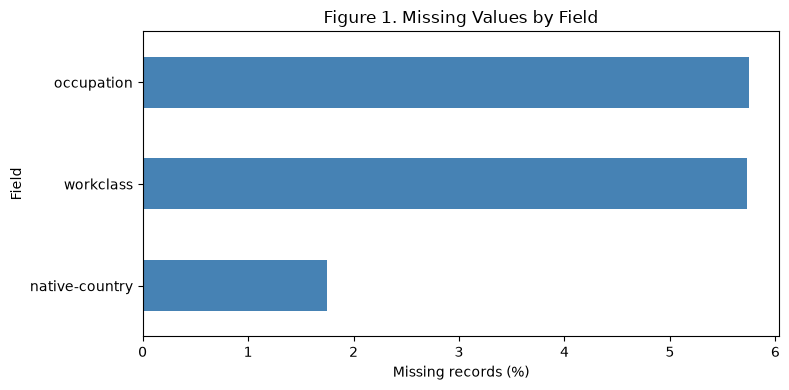

In [5]:
import matplotlib.pyplot as plt

missing_rates = profile.loc[
    profile["missing_count"] > 0, "missing_percent"
].sort_values()

missing_rates.plot.barh(figsize=(8, 4), color="steelblue")

plt.title("Figure 1. Missing Values by Field")
plt.xlabel("Missing records (%)")
plt.ylabel("Field")
plt.tight_layout()
plt.show()

**Interpretation:** Occupation and workclass have the highest missing rates, at 5.75% and 5.73%.

**Handling:** Dropping incomplete records would remove 3,620 rows (7.41%). We replace missing categories with `Unknown` and retain missingness flags, preserving records without inventing occupations or countries. `Unknown` represents unavailable information; it does not recover the missing facts.

In [6]:
clean = raw.copy()
clean[columns] = text_data.replace({"?": pd.NA, "": pd.NA})

missing_fields = profile.index[
    profile["missing_count"] > 0
].tolist()

missing_before = clean[missing_fields].isna().sum()

for col in missing_fields:
    clean[f"{col}_was_missing"] = clean[col].isna()
    clean[col] = clean[col].fillna("Unknown")

missing_check = pd.DataFrame({
    "missing_before": missing_before,
    "missing_after": clean[missing_fields].isna().sum(),
    "Unknown_count": clean[missing_fields].eq("Unknown").sum()
})

display(missing_check)

assert len(clean) == len(raw)

for col in missing_fields:
    assert clean[f"{col}_was_missing"].sum() == missing_before[col]

print("Records retained:", len(clean))

,missing_before,missing_after,Unknown_count
workclass,2799,0,2799
occupation,2809,0,2809
native-country,857,0,857


Records retained: 48842


## 7. Inconsistent Formats

We check whether formatting differences create extra categories. Equivalent labels should use one consistent format.

In [7]:
display(pd.crosstab(clean["source_split"], clean["income"]))

income,<=50K,<=50K.,>50K,>50K.
source_split,,,,
test,0,12435,0,3846
train,24720,0,7841,0


**Finding and handling:** Test-file income labels contain a trailing period, creating four labels instead of two. We remove only this suffix to merge equivalent labels. Leading and trailing whitespace was also stripped during preparation to prevent formatting differences from creating separate values.

In [8]:
income_before = clean["income"].value_counts()

clean["income"] = clean["income"].str.removesuffix(".")

income_check = pd.DataFrame({
    "before": income_before,
    "after": clean["income"].value_counts()
}).fillna(0).astype(int).sort_index()

display(income_check)

padding_before = raw[columns].apply(
    lambda col: col.ne(col.str.strip()).sum()
).sum()

padding_after = clean[columns].apply(
    lambda col: col.ne(col.str.strip()).sum()
).sum()

print("Padded cells before:", padding_before)
print("Padded cells after:", padding_after)
print("Income categories after:", clean["income"].nunique())

assert set(clean["income"].unique()) == {"<=50K", ">50K"}
assert padding_after == 0
assert len(clean) == len(raw)

,before,after
income,,
<=50K,24720,37155
<=50K.,12435,0
>50K,7841,11687
>50K.,3846,0


Padded cells before: 683788
Padded cells after: 0
Income categories after: 2


## 8. Numeric Types and Invalid Values

We validate numerical fields before converting them to integers. We also check plausible ranges. A value outside a validity rule requires investigation, while a statistically unusual value is not automatically an error.

In [9]:
numeric_columns = [
    "age", "fnlwgt", "education-num",
    "capital-gain", "capital-loss", "hours-per-week"
]

parsed = clean[numeric_columns].apply(
    pd.to_numeric, errors="coerce"
)

type_check = pd.DataFrame({
    "conversion_failures": (
        clean[numeric_columns].notna() & parsed.isna()
    ).sum(),
    "non_integer_values": (
        parsed.notna() & parsed.mod(1).ne(0)
    ).sum()
})

display(type_check)

assert type_check.to_numpy().sum() == 0
assert parsed.notna().all().all()

clean[numeric_columns] = parsed.astype("Int64")

display(clean[numeric_columns].dtypes.to_frame("type_after"))

,conversion_failures,non_integer_values
age,0,0
fnlwgt,0,0
education-num,0,0
capital-gain,0,0
capital-loss,0,0
hours-per-week,0,0


,type_after
age,Int64
fnlwgt,Int64
education-num,Int64
capital-gain,Int64
capital-loss,Int64
hours-per-week,Int64


In [10]:
invalid_values = pd.DataFrame({
    "age_outside_17_to_120": ~clean["age"].between(17, 120),
    "weight_not_above_1": clean["fnlwgt"] <= 1,
    "education_code_outside_1_to_16": ~clean["education-num"].between(1, 16),
    "negative_capital_gain": clean["capital-gain"] < 0,
    "negative_capital_loss": clean["capital-loss"] < 0,
    "hours_outside_1_to_168": ~clean["hours-per-week"].between(1, 168)
})

validity_check = pd.DataFrame({
    "invalid_count": invalid_values.sum(),
    "invalid_percent": (invalid_values.mean() * 100).round(2)
})

display(validity_check)

print("Records failing any rule:", invalid_values.any(axis=1).sum())

assert not invalid_values.any().any()

,invalid_count,invalid_percent
age_outside_17_to_120,0,0.0
weight_not_above_1,0,0.0
education_code_outside_1_to_16,0,0.0
negative_capital_gain,0,0.0
negative_capital_loss,0,0.0
hours_outside_1_to_168,0,0.0


Records failing any rule: 0


**Result and handling:** All six numerical fields were successfully converted to integers. No values violated the declared range rules, so no records were removed or values replaced. Zero capital amounts were retained as valid observations. Extreme but plausible values will be assessed separately using outlier checks.

## 9. Repeated Records

We compare all 15 original fields after standardisation. Source information and generated flags are excluded from the comparison. Because the dataset has no person identifier, identical profiles are flagged rather than automatically deleted.

In [11]:
repeated_rows = clean.duplicated(
    subset=columns, keep=False
)

extra_copies = clean.duplicated(
    subset=columns, keep="first"
)

clean["repeated_profile"] = repeated_rows

repeated_groups = clean.loc[repeated_rows].groupby(
    columns, dropna=False
)["source_split"].nunique()

duplicate_summary = pd.Series({
    "Extra matching rows": int(extra_copies.sum()),
    "Rows in repeated groups": int(repeated_rows.sum()),
    "Repeated profile groups": len(repeated_groups),
    "Groups appearing in both splits": int((repeated_groups > 1).sum())
}, name="count")

display(duplicate_summary.to_frame())

assert len(clean) == len(raw)
assert clean["repeated_profile"].sum() == repeated_rows.sum()

,count
Extra matching rows,52
Rows in repeated groups,101
Repeated profile groups,49
Groups appearing in both splits,23


**Result and handling:** There are 52 extra matching rows involving 101 records across 49 repeated-profile groups. We retain these records with a `repeated_profile` flag because matching attributes do not prove that they represent the same person.

Twenty-three repeated-profile groups occur in both training and test files. Before future modelling, this overlap should be investigated because it could affect evaluation results.

## 10. Outlier Detection and Handling

We use the IQR method to flag unusually low or high values:

- IQR = Q3 − Q1
- Lower fence = Q1 − 1.5 × IQR
- Upper fence = Q3 + 1.5 × IQR

Values outside these fences are flagged for review, not automatically treated as errors. Survey weights and education codes are excluded because they require different interpretation.

In [12]:
outlier_columns = [
    "age", "hours-per-week", "capital-gain", "capital-loss"
]

outlier_results = []

for col in outlier_columns:
    q1 = clean[col].quantile(0.25)
    q3 = clean[col].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    flags = (clean[col] < lower) | (clean[col] > upper)
    clean[f"{col}_iqr_flag"] = flags

    outlier_results.append({
        "field": col,
        "IQR": iqr,
        "lower_fence": lower,
        "upper_fence": upper,
        "flagged_count": int(flags.sum()),
        "flagged_percent": flags.mean() * 100
    })

outlier_summary = pd.DataFrame(
    outlier_results
).set_index("field")

display(outlier_summary.round(2))

,IQR,lower_fence,upper_fence,flagged_count,flagged_percent
field,,,,,
age,20.0,-2.0,78.0,216,0.44
hours-per-week,5.0,32.5,52.5,13496,27.63
capital-gain,0.0,0.0,0.0,4035,8.26
capital-loss,0.0,0.0,0.0,2282,4.67


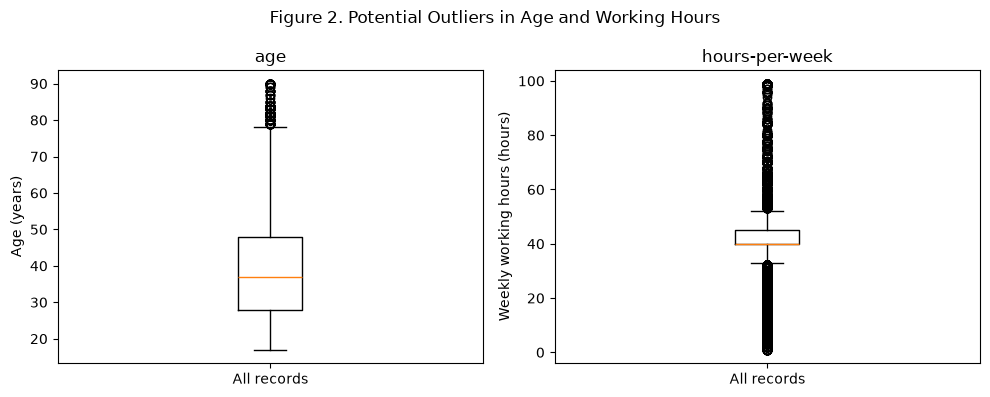

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

for ax, col, unit in zip(
    axes,
    ["age", "hours-per-week"],
    ["Age (years)", "Weekly working hours (hours)"]
):
    ax.boxplot(clean[col].astype(float), whis=1.5)
    ax.set_title(col)
    ax.set_ylabel(unit)
    ax.set_xticks([1])
    ax.set_xticklabels(["All records"])

fig.suptitle("Figure 2. Potential Outliers in Age and Working Hours")
plt.tight_layout()
plt.show()

**Interpretation:** The IQR rule flags 216 age values and 13,496 weekly-hours values, showing that unusual observations require investigation.

**Handling:** We retain the values and add outlier flags because they pass our validity checks. The weekly-hours fences are 32.5–52.5 hours, which also flag plausible part-time and long-hour workers. Removing these records could exclude legitimate groups.

For both capital fields, Q1 and Q3 are zero, so IQR flags every positive amount. This reflects their zero-heavy distributions rather than proving that positive amounts are errors. We retain these amounts with flags; their accuracy cannot be confirmed without further source verification.

In [14]:
for col in outlier_columns:
    original_values = pd.to_numeric(
        text_data[col], errors="raise"
    ).astype("Int64")

    pd.testing.assert_series_equal(
        clean[col], original_values
    )

assert len(clean) == len(raw)

print("Original numerical values and all records are retained.")

Original numerical values and all records are retained.


## 11. Privacy and Bias Risks

The dataset contains no names, phone numbers or email addresses. However, demographic attributes may reveal sensitive information or help identify individuals when linked with external data.

| Risk | Relevant fields or evidence | Mitigation |
|---|---|---|
| Re-identification | Age, country, education and occupation | Avoid linking records to identifying sources; share aggregate results and suppress small groups when necessary. |
| Sensitive information | Race, sex and income | Use these fields responsibly for bias checks; avoid decisions about individuals. |
| Unequal representation | Different group and income-class sizes | Report group counts and proportions; assess subgroup performance before future modelling. |
| Sampling and historical bias | Historical US data with extraction restrictions | Limit conclusions to this dataset; do not generalise to current Malaysian residents. |

Cleaning improves consistency but does not remove these risks.

In [15]:
balance_tables = []

for col in ["sex", "race", "income"]:
    table = clean[col].value_counts().rename_axis(
        "category"
    ).reset_index(name="count")

    table["percent"] = (
        table["count"] / len(clean) * 100
    ).round(2)

    table.insert(0, "field", col)
    balance_tables.append(table)

group_balance = pd.concat(
    balance_tables, ignore_index=True
)

display(group_balance)

,field,category,count,percent
0,sex,Male,32650,66.85
1,sex,Female,16192,33.15
2,race,White,41762,85.5
3,race,Black,4685,9.59
4,race,Asian-Pac-Islander,1519,3.11
5,race,Amer-Indian-Eskimo,470,0.96
6,race,Other,406,0.83
7,income,<=50K,37155,76.07
8,income,>50K,11687,23.93


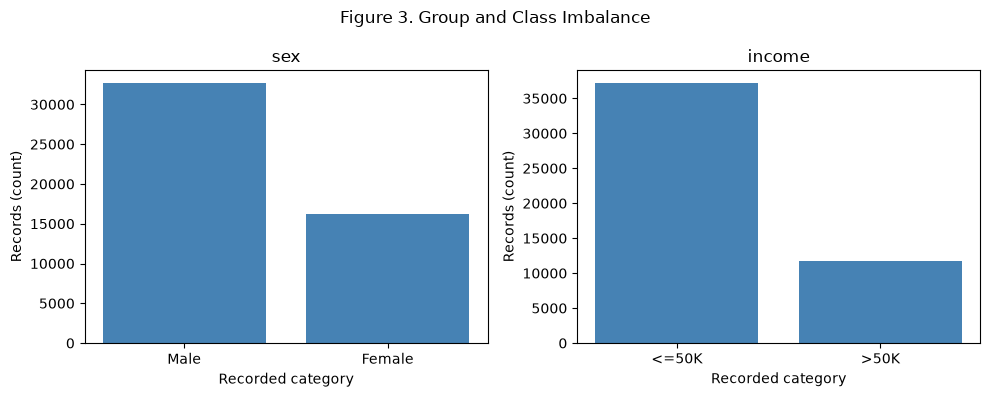

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

for ax, col in zip(axes, ["sex", "income"]):
    counts = clean[col].value_counts()

    ax.bar(counts.index, counts.values, color="steelblue")
    ax.set_title(col)
    ax.set_xlabel("Recorded category")
    ax.set_ylabel("Records (count)")

fig.suptitle("Figure 3. Group and Class Imbalance")
plt.tight_layout()
plt.show()

**Interpretation:** Male records account for 66.85% of the sample, while the `<=50K` income class accounts for 76.07%, showing unequal group representation and class balance.

**Handling:** We retain the original distribution rather than artificially balancing the dataset during cleaning. For future modelling, subgroup evaluation and class-sensitive metrics would be needed because overall accuracy could hide weaker results for smaller groups. Removing sensitive fields alone would not eliminate bias, as other attributes may act as proxies.

## 12. Cleaning Summary and Validation

We compare the data before and after processing, then verify that records, original numerical values and missingness information have been preserved. Unknown categories and review flags improve traceability but do not resolve the underlying uncertainty.

In [17]:
audit = pd.DataFrame([
    [
        "Missing cells",
        int(missing_mask.sum().sum()),
        int(clean[columns].isna().sum().sum()),
        "Replace with Unknown and retain missingness flags"
    ],
    [
        "Padded cells",
        int(padding_before),
        int(padding_after),
        "Strip leading and trailing whitespace"
    ],
    [
        "Income categories",
        raw["income"].str.strip().nunique(),
        clean["income"].nunique(),
        "Remove the trailing period"
    ],
    [
        "Numeric fields stored as text",
        len(numeric_columns),
        sum(str(clean[col].dtype) == "string" for col in numeric_columns),
        "Validate and convert to integers"
    ],
    [
        "Records",
        len(raw),
        len(clean),
        "Retain records with review flags"
    ]
], columns=["check", "before", "after", "handling"])

display(audit)

assert len(clean) == len(raw)
assert not clean[columns].isna().any().any()
assert not clean[columns].isin(["?", ""]).any().any()
assert set(clean["income"].unique()) == {"<=50K", ">50K"}
assert all(str(clean[col].dtype) == "Int64" for col in numeric_columns)
assert not invalid_values.any().any()

for col in missing_fields:
    expected_missing = missing_mask[col].astype(bool)

    assert clean[f"{col}_was_missing"].astype(bool).equals(
        expected_missing
    )

    assert clean[col].eq("Unknown").astype(bool).equals(
        expected_missing
    )

for col in numeric_columns:
    expected_values = pd.to_numeric(
        text_data[col], errors="raise"
    ).astype("Int64")

    pd.testing.assert_series_equal(
        clean[col], expected_values
    )

assert clean["repeated_profile"].equals(
    clean.duplicated(subset=columns, keep=False)
)

pd.testing.assert_series_equal(
    clean["source_split"], raw["source_split"]
)

print("Validation passed.")
print("Records retained:", len(clean))

,check,before,after,handling
0,Missing cells,6465,0,Replace with Unknown and retain missingness flags
1,Padded cells,683788,0,Strip leading and trailing whitespace
2,Income categories,4,2,Remove the trailing period
3,Numeric fields stored as text,6,0,Validate and convert to integers
4,Records,48842,48842,Retain records with review flags


Validation passed.
Records retained: 48842


In [18]:
output_dir = Path("outputs")
output_dir.mkdir(exist_ok=True)

clean.to_csv(
    output_dir / "adult_cleaned.csv",
    index=False
)

audit.to_csv(
    output_dir / "cleaning_summary.csv",
    index=False
)

profile.to_csv(
    output_dir / "initial_profile.csv",
    index_label="field"
)

outlier_summary.to_csv(
    output_dir / "outlier_summary.csv",
    index_label="field"
)

group_balance.to_csv(
    output_dir / "group_balance.csv",
    index=False
)

print("Output files saved:")
for path in sorted(output_dir.glob("*.csv")):
    print(path.name)

Output files saved:
adult_cleaned.csv
cleaning_summary.csv
group_balance.csv
initial_profile.csv
outlier_summary.csv


## 13. Conclusion

The processed dataset is conditionally suitable for an educational study of historical US census-income records. We represented 6,465 missing cells as `Unknown` with missingness flags, standardised whitespace and income labels, and converted six numerical fields to integers. All 48,842 records were retained, and no numerical values violated the declared validity rules.

Repeated profiles and IQR-flagged values were retained with flags because identical attributes do not prove person identity, and unusual values may be legitimate. The 23 repeated-profile groups shared across training and test files require investigation before future modelling.

Limitations remain: `Unknown` does not recover missing information, extreme values are not independently verified, and cleaning does not eliminate sampling or demographic bias. The dataset should not be treated as representative of current Malaysian residents or used to make decisions about individuals without further validation.